# Attention Mechanism In-depth Architecture Explanation

## Introduction to Attention Mechanism

When using encoder-decoder (sequence-to-sequence) models, the context vector created by the encoder may not be enough for the decoder to generate accurate outputs, especially for long sentences. This is seen as a drop in BLEU score as sentence length increases.

The attention mechanism solves this by giving the decoder more context, no matter how long the input is. This helps the decoder generate better outputs.

The concept was introduced in the paper "Neural Machine Translation by Jointly Learning to Align and Translate" by Yoshua Bengio and colleagues. The paper improved the encoder-decoder framework by adding attention.

---

## Revisiting Encoder-Decoder Architecture

- The encoder (LSTM) processes a sequence of inputs (e.g., "Hello", "What's", "up").
- The encoder outputs:
  - $s_0$: the hidden state
  - $c$: the context vector
- These are passed to the decoder, which is also an LSTM.
- The decoder's first input is $y_0$ (start-of-sequence token or ground truth during training).
- At each step, the decoder uses the previous output and the context vector to predict the next word.
- The predicted output is fed as input to the next decoder step, along with the same context vector, until the end of the sequence.

---

## Limitations of the Traditional Architecture

- The context vector $c$ is fixed and summarizes the whole input sequence into a single vector.
- For long sentences, this single vector can't capture all the important information, especially from earlier words.
- As a result, the decoder's performance drops for long sentences (lower BLEU score).

---

## Attention Mechanism Architecture

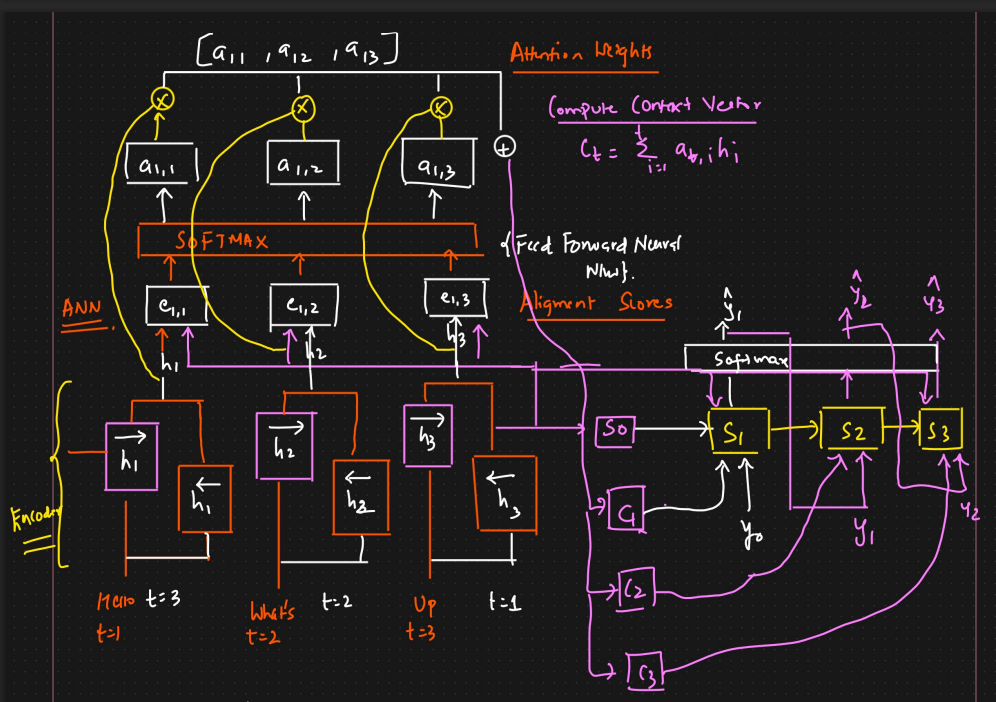

**Key changes:**
- The encoder uses a bidirectional LSTM to capture context from both past and future tokens.
- Instead of a single context vector, the decoder gets a dynamically computed context vector at each time step.

### Bidirectional LSTM Encoder

- Processes the input sequence in both directions.
- Produces forward hidden states ($h_1, h_2, h_3$) and backward hidden states ($\overleftarrow{h}_3, \overleftarrow{h}_2, \overleftarrow{h}_1$).
- These are combined for each time step: $\tilde{h}_i = [h_i; \overleftarrow{h}_i]$.

### Alignment Scores and Attention Weights

- At each decoder step $t$, compute alignment scores between the previous decoder hidden state $s_{t-1}$ and each encoder output $\tilde{h}_i$:
  $$
  e_{t,i} = \text{score}(s_{t-1}, \tilde{h}_i)
  $$
- Use a feed-forward network and softmax to get attention weights:
  $$
  a_{t,i} = \frac{\exp(e_{t,i})}{\sum_{k=1}^T \exp(e_{t,k})}
  $$
- These weights show how much the decoder should focus on each encoder output at time $t$.

### Computing the Context Vector

- The context vector at decoder step $t$ is a weighted sum of encoder outputs:
  $$
  c_t = \sum_{i=1}^T a_{t,i} \tilde{h}_i
  $$

### Decoder with Attention

- At each decoder step $t$, the decoder gets:
  - Previous hidden state $s_{t-1}$
  - Context vector $c_t$
  - Previous output $y_{t-1}$
- The decoder computes the current hidden state $s_t$ and predicts the output $\hat{y}_t$ via a softmax layer.
- The context vector $c_t$ is recalculated at every step.

---

## Summary

- The attention mechanism lets the decoder focus on different parts of the input sequence at each step, not just a fixed context vector.
- This improves translation quality, especially for long sentences, and keeps BLEU scores high.
- This architecture is the basis for modern transformer models and generative AI.

---

## Key Takeaways

- Attention gives the decoder more context, especially for long sentences.
- The encoder uses bidirectional LSTM for richer representations.
- Alignment scores and attention weights decide how much context from each encoder output to use at each decoder step.
- The context vector is dynamically computed at every decoder step, improving translation quality for all sentence lengths.